

## **> Day 1 실습 : Ligand Prepration**



In [1]:
# STEP 0: 도구 설치 — RDKit(분자), Meeko(도킹용 변환), Vina(도킹), gemmi(구조 정리), py3Dmol(3D 뷰)
!pip -q install rdkit "meeko==0.7.1" vina gemmi py3Dmol
print("설치 완료")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.0/294.0 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 32.7 MB/s eta 0:00:00
설치 완료


SMILES 문자열 : N=C(N)c1ccccc1
→ 구조표현


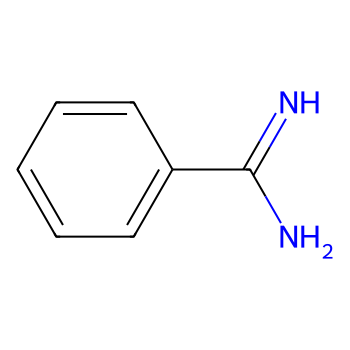

In [15]:
from rdkit import Chem
from rdkit.Chem import Draw

# 오늘의 리간드: Ethanol (에탄올)
LIGAND_SMILES = "N=C(N)c1ccccc1"

mol2d = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"SMILES 문자열 : {LIGAND_SMILES}")
print(f"→ 구조표현")

Draw.MolToImage(mol2d, size=(350, 350))   # 2D 그림으로 확인

In [16]:
from rdkit.Chem import AllChem
import py3Dmol

mol = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"Heavy Atom {mol.GetNumAtoms()}개 (수소 없음, 3차원 구조 없음)")

AllChem.EmbedMolecule(mol, randomSeed=42)   # 무거운 원자만으로 3D 배치
print("→ 현재 상태로 3D 골격 생성")

view = py3Dmol.view(width=450, height=450)
view.addModel(Chem.MolToMolBlock(mol), 'mol')
view.setStyle({'stick': {}, 'sphere': {'scale': 0.3}})
view.setBackgroundColor('white'); view.zoomTo()
view.show()

[RDKit] WARNING:[05:33:52] Molecule does not have explicit Hs. Consider calling AddHs()


Heavy Atom 9개 (수소 없음, 3차원 구조 없음)
→ 현재 상태로 3D 골격 생성


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [17]:
from rdkit.Chem import AllChem

# 1) SMILES 파싱 (아직 3D 없음, 수소 없음)
mol = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"[1] 파싱 직후    : 원자 {mol.GetNumAtoms()}개, 3D 좌표 없음, 수소 없음")

# 2) 수소 추가 — 도킹 점수함수엔 수소가 필요
mol = Chem.AddHs(mol)
print(f"[2] 수소 추가 후 : 원자 {mol.GetNumAtoms()}개  ← 수소가 붙어서 늘어남")

# 3) 3D 좌표 생성 (embedding) — 평면 글자를 입체 구조로
AllChem.EmbedMolecule(mol, randomSeed=42)
conf = mol.GetConformer()
p = conf.GetAtomPosition(0)
print(f"[3] 3D 좌표 생성 : 이제 각 원자에 (x,y,z)가 생김")
print(f"    예) 0번 원자 위치 = ({p.x:.2f}, {p.y:.2f}, {p.z:.2f})")

# 4) 구조 최적화 — 에너지적으로 자연스러운 모양으로 다듬기
AllChem.MMFFOptimizeMolecule(mol)
print(f"[4] 3차원 구조 생성 완료")

[1] 파싱 직후    : 원자 9개, 3D 좌표 없음, 수소 없음
[2] 수소 추가 후 : 원자 17개  ← 수소가 붙어서 늘어남
[3] 3D 좌표 생성 : 이제 각 원자에 (x,y,z)가 생김
    예) 0번 원자 위치 = (2.16, -1.49, -0.03)
[4] 3차원 구조 생성 완료


In [18]:
import py3Dmol

view = py3Dmol.view(width=450, height=450)
view.addModel(Chem.MolToMolBlock(mol), 'mol')
view.setStyle({'stick': {}})
view.setBackgroundColor('white')
view.zoomTo()
print("흰색 원자(수소)가 preparation 단계에서 새로 붙은 것들입니다. 마우스로 돌려보세요.")
view.show()

흰색 원자(수소)가 preparation 단계에서 새로 붙은 것들입니다. 마우스로 돌려보세요.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [19]:
import py3Dmol, math
from rdkit import Chem
from rdkit.Chem import AllChem

# Meeko가 얹는 것과 같은 방식(Gasteiger)의 부분전하 계산
AllChem.ComputeGasteigerCharges(mol)
conf = mol.GetConformer()

view = py3Dmol.view(width=460, height=460)
view.addModel(Chem.MolToMolBlock(mol), "mol")
view.setStyle({"stick": {}})

for atom in mol.GetAtoms():
    if atom.GetSymbol() == "H":
        continue                      # 수소 라벨은 생략(복잡해짐)
    q = atom.GetDoubleProp("_GasteigerCharge")
    if math.isnan(q):
        continue
    p = conf.GetAtomPosition(atom.GetIdx())
    view.addLabel(f"{q:+.2f}", {
        "position": {"x": p.x, "y": p.y, "z": p.z},
        "fontSize": 11,
        "fontColor": "red" if q < 0 else "blue",   # 빨강 −, 파랑 +
        "backgroundColor": "white", "backgroundOpacity": 0.7,
    })

view.setBackgroundColor("white")
view.zoomTo()
print("각 원자의 부분전하(빨강 −, 파랑 +). 구조는 그대로지만 '전하'라는 정보가 추가.")
view.show()

각 원자의 부분전하(빨강 −, 파랑 +). 구조는 그대로지만 '전하'라는 정보가 추가.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [20]:
from rdkit import Chem
from rdkit.Chem import AllChem
from meeko import MoleculePreparation, PDBQTWriterLegacy

# LIGAND_SMILES에서 도킹용 리간드를 매번 새로 준비 (항상 최신 SMILES 기준)
_lig = Chem.AddHs(Chem.MolFromSmiles(LIGAND_SMILES))
if AllChem.EmbedMolecule(_lig, randomSeed=42) != 0:                 # 실패 시(큰 분자)
    AllChem.EmbedMolecule(_lig, randomSeed=42, useRandomCoords=True)
AllChem.MMFFOptimizeMolecule(_lig)

pdbqt_string = PDBQTWriterLegacy.write_string(MoleculePreparation().prepare(_lig)[0])[0]
with open("ligand.pdbqt", "w") as f:
    f.write(pdbqt_string)

smi = next((l for l in pdbqt_string.splitlines() if "REMARK SMILES" in l), "")
print(f"리간드 준비 완료 (지금 SMILES = {LIGAND_SMILES})")
print(" ", smi)

리간드 준비 완료 (지금 SMILES = N=C(N)c1ccccc1)
  REMARK SMILES N=C(N)c1ccccc1




## **> Day 1 실습 : Protein Prepration**



In [21]:
# 단백질 준비 STEP 1: PDB ID로 실험 구조 받기
import urllib.request, os

PDB_ID = "3PTB"   # ← 여기만 바꾸면 다른 단백질도 받아짐 (예: 1IEP)

filename = f"{PDB_ID}.pdb"
urllib.request.urlretrieve(f"https://files.rcsb.org/download/{filename}", filename)
print(f"{filename} 다운로드 완료:", os.path.getsize(filename), "bytes")

3PTB.pdb 다운로드 완료: 183384 bytes


In [22]:
import py3Dmol
from collections import Counter

pdb = open(filename).read()   # filename = 앞 셀에서 받은 "3PTB.pdb"

# (1) 단백질 외에 뭐가 섞여 있나 — 텍스트로 요약
het = Counter(line[17:20].strip() for line in pdb.splitlines() if line.startswith("HETATM"))
print("단백질(ATOM) 말고 파일에 섞여 있는 것들 (HETATM):")
for name, n in het.most_common():
    print(f"  {name} : {n} atoms")

# (2) 3D로 관찰 — 회색 단백질 / 초록 벤즈아미딘 / 빨강 물 / 보라 이온
view = py3Dmol.view(width=600, height=500)
view.addModel(pdb, "pdb")
view.setStyle({"cartoon": {"color": "lightgray"}})                              # 단백질
view.addStyle({"resn": "BEN"}, {"stick": {"colorscheme": "greenCarbon"}})       # 정답 리간드
view.addStyle({"resn": "HOH"}, {"sphere": {"scale": 0.25, "color": "red"}})     # 물
view.addStyle({"resn": "CA"},  {"sphere": {"scale": 0.45, "color": "purple"}})  # 칼슘 이온
view.setBackgroundColor("white")
view.zoomTo()
print("Protein과 ligand 외 다수 불필요한 분자 정리 필요.")
view.show()

단백질(ATOM) 말고 파일에 섞여 있는 것들 (HETATM):
  HOH : 62 atoms
  BEN : 9 atoms
  CA : 1 atoms
Protein과 ligand 외 다수 불필요한 분자 정리 필요.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [23]:
import gemmi, py3Dmol

# 경로는 PDB_ID 하나에서만 결정 → 변수 꼬임 방지
filename   = f"{PDB_ID}.pdb"
clean_file = f"{PDB_ID}_clean.pdb"

# --- 정리 ---
st = gemmi.read_structure(filename)
before = sum(1 for ch in st[0] for res in ch for a in res)
st.setup_entities()
st.remove_alternative_conformations()
st.remove_hydrogens()
st.remove_ligands_and_waters()
st.remove_empty_chains()
after = sum(1 for ch in st[0] for res in ch for a in res)
st.write_pdb(clean_file)
print(f"[{PDB_ID}] 청소 전 {before} → 청소 후 {after} atoms")
leftover = {l[17:20].strip() for l in open(clean_file) if l.startswith("HETATM")}
print("남은 HETATM:", leftover or "없음 — 단백질만 남음 ✅")

# --- 정리 전/후 좌우 비교 (둘 다 현재 PDB_ID 기준) ---
view = py3Dmol.view(width=820, height=450, viewergrid=(1, 2))
# 왼쪽: 정리 전 — 비단백질(물·리간드·이온) 전부 빨강
view.addModel(open(filename).read(), "pdb", viewer=(0, 0))
view.setStyle({"cartoon": {"color": "lightgray"}}, viewer=(0, 0))
view.addStyle({"hetflag": True},
              {"stick": {"colorscheme": "redCarbon"}, "sphere": {"scale": 0.3}},
              viewer=(0, 0))
# 오른쪽: 정리 후 — 단백질만
view.addModel(open(clean_file).read(), "pdb", viewer=(0, 1))
view.setStyle({"cartoon": {"color": "lightgray"}}, viewer=(0, 1))
view.setBackgroundColor("white")
view.zoomTo()
print("\n왼쪽 = 정리 전(빨강=물·리간드·이온)   →   오른쪽 = 정리 후(단백질만)")
view.show()

[3PTB] 청소 전 1701 → 청소 후 1629 atoms
남은 HETATM: 없음 — 단백질만 남음 ✅

왼쪽 = 정리 전(빨강=물·리간드·이온)   →   오른쪽 = 정리 후(단백질만)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [24]:
import subprocess
clean_file = f"{PDB_ID}_clean.pdb"
out_base   = f"{PDB_ID}_receptor"
receptor_pdbqt = f"{out_base}.pdbqt"

r = subprocess.run(["mk_prepare_receptor.py", "--read_pdb", clean_file, "-o", out_base, "-p"],
                   capture_output=True, text=True)
if r.returncode != 0:
    print("⚠️ 에러:\n", r.stderr[-1500:])   # 다른 단백질에서 실패하면 이 내용 알려주세요
else:
    n = sum(l.startswith("ATOM") for l in open(receptor_pdbqt))
    print(f"[{PDB_ID}] receptor 준비 완료 → {receptor_pdbqt} ({n} atoms)")

[3PTB] receptor 준비 완료 → 3PTB_receptor.pdbqt (2009 atoms)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
import py3Dmol

receptor_pdbqt = f"{PDB_ID}_receptor.pdbqt"

view = py3Dmol.view(width=550, height=500)
view.addModel(open(receptor_pdbqt).read(), "pdbqt")
view.setStyle({"cartoon": {"color": "spectrum"}})           # 단백질 뼈대
view.addSurface(py3Dmol.VDW, {"opacity": 0.5, "color": "white"})  # 표면(도킹 대상 느낌)
view.setBackgroundColor("white")
view.zoomTo()
print(f"{PDB_ID} receptor 준비 완료 — 수소·전하·원자타입이 부여된 도킹 대상 단백질")
view.show()

3PTB receptor 준비 완료 — 수소·전하·원자타입이 부여된 도킹 대상 단백질


3Dmol.js failed to load for some reason. Please check your browser console for error messages.



## **> Day 1 실습 : Molecular Docking**



In [28]:
import gemmi, numpy as np, py3Dmol

st = gemmi.read_structure(f"{PDB_ID}.pdb")
SKIP = {"HOH","NA","CL","CA","MG","ZN","K","MN","FE","CU","SO4","PO4","GOL","EDO","ACT","DMS","PEG"}

# 리간드 후보를 (체인, 잔기) '인스턴스' 단위로 수집 → dimer면 복사본이 따로 잡힘
instances = []
for ch in st[0]:
    for res in ch:
        if res.name in SKIP:
            continue
        info = gemmi.find_tabulated_residue(res.name)
        if info and (info.is_amino_acid() or info.is_nucleic_acid()):
            continue
        coords = [[a.pos.x, a.pos.y, a.pos.z] for a in res]
        instances.append((len(coords), ch.name, res.name, res.seqid.num, coords))

# 복사본 평균이 아니라 '단일 리간드 하나'를 선택
_, LIG_CHAIN, ligname, LIG_SEQID, coords = max(instances, key=lambda t: t[0])
xyz = np.array(coords)
box_center = xyz.mean(0).round(2).tolist()
box_size   = (xyz.max(0) - xyz.min(0) + 8).round(1).tolist()
print(f"리간드 '{ligname}' (chain {LIG_CHAIN}, res {LIG_SEQID}, {len(coords)} atoms)")
print(f"  → 박스 중심 {box_center}, 크기 {box_size}")

# 선택된 그 리간드 '하나'만 뽑는 헬퍼 (뒤 RMSD 셀에서도 재사용)
def one_ligand(pdb_path):
    return "".join(l for l in open(pdb_path)
                   if l.startswith("HETATM") and l[17:20].strip()==ligname
                      and l[21]==LIG_CHAIN and l[22:26].strip()==str(LIG_SEQID))

# 박스 확인
view = py3Dmol.view(width=560, height=500)
view.addModel(open(f"{PDB_ID}_clean.pdb").read(), "pdb")
view.setStyle({"cartoon": {"color": "lightgray"}})
view.addModel(one_ligand(f"{PDB_ID}.pdb"), "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "orangeCarbon"}})
cx, cy, cz = box_center; sx, sy, sz = box_size
view.addBox({"center": {"x": cx, "y": cy, "z": cz},
             "dimensions": {"w": sx, "h": sy, "d": sz},
             "color": "orange", "opacity": 0.35})
view.zoomTo({"model": 1})
view.setBackgroundColor("white")
print("주황 상자 = 단일 리간드 자리에 맞춘 탐색 공간 (dimer의 한쪽만)")
view.show()

리간드 'BEN' (chain A, res 1, 9 atoms)
  → 박스 중심 [-1.76, 14.46, 16.92], 크기 [9.9, 12.0, 12.5]
주황 상자 = 단일 리간드 자리에 맞춘 탐색 공간 (dimer의 한쪽만)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [29]:
from vina import Vina

# 리간드 준비 결과(pdbqt_string)를 파일로 저장
ligand_pdbqt = "ligand.pdbqt"
with open(ligand_pdbqt, "w") as f:
    f.write(pdbqt_string)

receptor_pdbqt = f"{PDB_ID}_receptor.pdbqt"

v = Vina(sf_name="vina", verbosity=0)
v.set_receptor(receptor_pdbqt)
v.set_ligand_from_file(ligand_pdbqt)
v.compute_vina_maps(center=box_center, box_size=box_size)   # 앞 셀의 박스
v.dock(exhaustiveness=8, n_poses=5)
v.write_poses("docked.pdbqt", n_poses=5, overwrite=True)

print("mode |  affinity (kcal/mol)")
print("-----+--------------------")
for i, row in enumerate(v.energies(n_poses=5), 1):
    print(f"  {i}  |   {row[0]:8.2f}")
print("\n낮을수록(더 음수) 강한 결합. 1위가 Vina의 최선의 추측.")

mode |  affinity (kcal/mol)
-----+--------------------
  1  |      -6.06
  2  |      -5.04
  3  |      -5.04
  4  |      -4.91
  5  |      -4.72

낮을수록(더 음수) 강한 결합. 1위가 Vina의 최선의 추측.


In [30]:
import py3Dmol
from rdkit import Chem
from meeko import PDBQTMolecule, RDKitMolCreate

# 도킹 결과(PDBQT)를 RDKit 분자로 복원 → 결합 정보 완전 (고리도 제대로 그려짐)
pmol = PDBQTMolecule.from_file("docked.pdbqt", skip_typing=True)
lig  = Chem.RemoveHs(RDKitMolCreate.from_pdbqt_mol(pmol)[0])   # 수소 빼서 깔끔하게
pose1_block = Chem.MolToMolBlock(lig, confId=0)                # confId=0 = 1위 pose

view = py3Dmol.view(width=600, height=520)
view.addModel(open(f"{PDB_ID}_clean.pdb").read(), "pdb")       # 단백질
view.setStyle({"cartoon": {"color": "lightgray"}})
view.addModel(pose1_block, "mol")                             # 도킹 1위(초록)
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon"}})
view.zoomTo({"model": 1})
view.setBackgroundColor("white")
print("초록 = 도킹 1위 pose (단백질 주머니에 앉은 모습)")
view.show()

초록 = 도킹 1위 pose (단백질 주머니에 앉은 모습)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [31]:
import py3Dmol
from rdkit import Chem
from meeko import PDBQTMolecule, RDKitMolCreate

# 도킹 1위 pose 복원 (결합 정보 완전)
pmol = PDBQTMolecule.from_file("docked.pdbqt", skip_typing=True)
lig  = Chem.RemoveHs(RDKitMolCreate.from_pdbqt_mol(pmol)[0])
pose1_block = Chem.MolToMolBlock(lig, confId=0)

# 결정구조 정답 리간드 (원본 PDB의 co-crystal 리간드)
crystal_block = one_ligand(f"{PDB_ID}.pdb")   # 박스 셀에서 고른 그 한 copy

protein = open(f"{PDB_ID}_clean.pdb").read()

view = py3Dmol.view(width=860, height=460, viewergrid=(1, 2))

# 왼쪽: 결정구조 정답 pose (자홍)
view.addModel(protein, "pdb", viewer=(0, 0))
view.addModel(crystal_block, "pdb", viewer=(0, 0))
view.setStyle({"cartoon": {"color": "lightgray"}}, viewer=(0, 0))
view.setStyle({"model": 1}, {"stick": {"colorscheme": "magentaCarbon"}}, viewer=(0, 0))
view.zoomTo({"model": 1}, viewer=(0, 0))

# 오른쪽: 도킹 1위 pose (초록)
view.addModel(protein, "pdb", viewer=(0, 1))
view.addModel(pose1_block, "mol", viewer=(0, 1))
view.setStyle({"cartoon": {"color": "lightgray"}}, viewer=(0, 1))
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon"}}, viewer=(0, 1))
view.zoomTo({"model": 1}, viewer=(0, 1))

view.setBackgroundColor("white")
print("왼쪽 = 결정구조 정답(자홍)   |   오른쪽 = 도킹 1위(초록)")
view.show()

왼쪽 = 결정구조 정답(자홍)   |   오른쪽 = 도킹 1위(초록)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [32]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign
from meeko import PDBQTMolecule, RDKitMolCreate
import py3Dmol, gemmi

# 결정 리간드 한 copy 추출
st = gemmi.read_structure(f"{PDB_ID}.pdb")
SKIP = {"HOH","NA","CL","CA","MG","ZN","K","MN","FE","CU","SO4","PO4","GOL","EDO","ACT","DMS","PEG"}
inst=[]
for ch in st[0]:
    for res in ch:
        if res.name in SKIP: continue
        info=gemmi.find_tabulated_residue(res.name)
        if info and (info.is_amino_acid() or info.is_nucleic_acid()): continue
        inst.append((len([a for a in res]), ch.name, res.name, res.seqid.num))
_, lc, ln, ls = max(inst, key=lambda t: t[0])
crystal_block="".join(l for l in open(f"{PDB_ID}.pdb")
                      if l.startswith("HETATM") and l[17:20].strip()==ln
                         and l[21]==lc and l[22:26].strip()==str(ls))

# 도킹 1위 pose 복원
pmol=PDBQTMolecule.from_file("docked.pdbqt", skip_typing=True)
dock=Chem.RemoveHs(RDKitMolCreate.from_pdbqt_mol(pmol)[0])
crystal_raw=Chem.MolFromPDBBlock(crystal_block, sanitize=False)

# 같은 분자인지 먼저 확인 (RMSD는 redocking일 때만 의미)
if crystal_raw.GetNumAtoms() != dock.GetNumAtoms():
    print(f"   도킹 리간드 {dock.GetNumAtoms()}개 ≠ 결정 리간드 {ln} {crystal_raw.GetNumAtoms()}개 — 다른 분자입니다.")
    print(f"   현재 LIGAND_SMILES = {LIGAND_SMILES}")
    print("   해결: LIGAND_SMILES를 결정 리간드와 같게(3PTB면 벤즈아미딘 c1ccc(cc1)C(=N)N) 바꾸고")
    print("        리간드 준비 → 도킹 셀부터 다시 실행 → 그다음 이 셀.")
else:
    crystal = AllChem.AssignBondOrdersFromTemplate(dock, crystal_raw)   # 도킹 분자를 템플릿으로 (견고)
    rmsd = rdMolAlign.CalcRMS(dock, crystal, 0, 0)
    verdict = "성공 (2 Å 미만)" if rmsd < 2.0 else "재검토 필요 ✗ (2 Å 이상)"
    print(f"결정 리간드 {ln} · RMSD = {rmsd:.2f} Å  →  {verdict}")

    view=py3Dmol.view(width=600,height=520)
    view.addModel(open(f"{PDB_ID}_clean.pdb").read(),"pdb"); view.setStyle({"cartoon":{"color":"lightgray"}})
    view.addModel(Chem.MolToMolBlock(crystal),"mol"); view.setStyle({"model":1},{"stick":{"colorscheme":"magentaCarbon"}})
    view.addModel(Chem.MolToMolBlock(dock,confId=0),"mol"); view.setStyle({"model":2},{"stick":{"colorscheme":"greenCarbon"}})
    view.zoomTo({"model":1}); view.setBackgroundColor("white")
    print("자홍=결정 정답, 초록=도킹 1위. 겹칠수록 재현 성공.")
    view.show()

[RDKit] WARNING:[05:49:08] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:


결정 리간드 BEN · RMSD = 0.40 Å  →  성공 (2 Å 미만)
자홍=결정 정답, 초록=도킹 1위. 겹칠수록 재현 성공.


3Dmol.js failed to load for some reason. Please check your browser console for error messages.